<div >
<img src = "../banner.jpg" />
</div>

<a target="_blank" href="https://colab.research.google.com/github/ignaciomsarmiento/BDML_2026_20/blob/main/Lecture13/02_Convolution_Pooling.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

# Convolución y pooling

Este cuderno busca implementar **a mano** las dos operaciones centrales de una CNN, la convolución y el *max pooling*, para ver exactamente qué hacen.

## Llamando las librerías

In [23]:
# install.packages("pacman") #Correr esta linea en Google Colab

In [24]:
require("pacman")
p_load("imager", "tidyverse")

set.seed(20261104)

## 1. Convolución sobre una matriz pequeña

Una convolución coloca un filtro (o *kernel*) de $k\times k$ sobre una región de la imagen, multiplica elemento por elemento, suma y agrega un sesgo:

$$ z_{i,j} = \sum_{r}\sum_{c} W_{r,c}\, X_{i+r,\,j+c} + b $$

Escribimos primero la función para **una** posición, y después la que recorre toda la imagen.

In [25]:
# Convolución en una posición (x, y): producto punto entre el filtro y la región centrada ahí
convolve <- function(img, filter_, k, x, y) {
  suma <- 0
  k_start <- -floor(k / 2)
  for (i in 0:(k - 1)) {
    for (j in 0:(k - 1)) {
      img_y <- y + i + k_start
      img_x <- x + j + k_start
      suma <- suma + img[img_y, img_x] * filter_[i + 1, j + 1]
    }
  }
  return(suma)
}

# Convolución "valid": solo las posiciones donde el filtro cabe entero
convolve_image <- function(img, filter_, bias = 0) {
  k <- nrow(filter_)
  height <- nrow(img)
  width  <- ncol(img)
  margen <- floor(k / 2)
  salida <- matrix(0, nrow = height - 2 * margen, ncol = width - 2 * margen)
  for (y in (margen + 1):(height - margen)) {
    for (x in (margen + 1):(width - margen)) {
      salida[y - margen, x - margen] <- convolve(img, filter_, k, x, y) + bias
    }
  }
  return(salida)
}

### Un primer ejemplo: $4\times4$ con un filtro vertical

El filtro tiene unos en la columna central: suma los tres píxeles de una columna.

In [26]:
img_4x4 <- matrix(c(0, 3, 6, 9,
                    1, 4, 7, 10,
                    2, 5, 8, 11,
                    3, 6, 9, 12), nrow = 4, byrow = TRUE)

filtro_vertical <- matrix(c(0, 1, 0,
                            0, 1, 0,
                            0, 1, 0), nrow = 3, byrow = TRUE)

convolve_image(img_4x4, filtro_vertical)

12,21
15,24


Con una imagen de $4\times4$ y un filtro de $3\times3$, el filtro cabe en $2\times2$ posiciones. En general, sin *padding* y con *stride* 1, el output es de $(n-k+1)\times(n-k+1)$.

### El ejemplo de las slides: la O de $6\times6$

Codificamos la imagen con 1 para los píxeles negros y 0 para los blancos. El filtro tiene unos en la antidiagonal y el sesgo es $-2$.

In [27]:
imagen_O <- matrix(c(0, 0, 1, 1, 0, 0,
                     0, 1, 0, 0, 1, 0,
                     1, 0, 0, 0, 0, 1,
                     1, 0, 0, 0, 0, 1,
                     0, 1, 0, 0, 1, 0,
                     0, 0, 1, 1, 0, 0), nrow = 6, byrow = TRUE)

filtro_antidiagonal <- matrix(c(0, 0, 1,
                                0, 1, 0,
                                1, 0, 0), nrow = 3, byrow = TRUE)

feature_map <- convolve_image(imagen_O, filtro_antidiagonal, bias = -2)
feature_map

1,-1,-2,-1
-1,-2,-1,-2
-2,-1,-2,-1
-1,-2,-1,1


Es el *feature map* de $4\times4$ de las slides: en la esquina superior izquierda el filtro encuentra sus tres unos ($1+1+1-2=1$); un lugar a la derecha encuentra uno solo ($1-2=-1$).

### ReLU

La activación se aplica elemento por elemento: $\operatorname{ReLU}(z)=\max(0,z)$.

In [28]:
relu <- function(z) pmax(z, 0)  # el primer argumento conserva las dimensiones de la matriz

feature_map_relu <- relu(feature_map)
feature_map_relu

1,0,0,0
0,0,0,0
0,0,0,0
0,0,0,1


## 2. Filtros conocidos sobre una imagen

En procesamiento de imágenes los filtros se eligen a mano. Veamos qué hacen algunos filtros clásicos sobre una imagen en escala de grises. Cargamos la imagen desde internet para que el cuaderno corra en Colab.

[1] 512 512   1   1

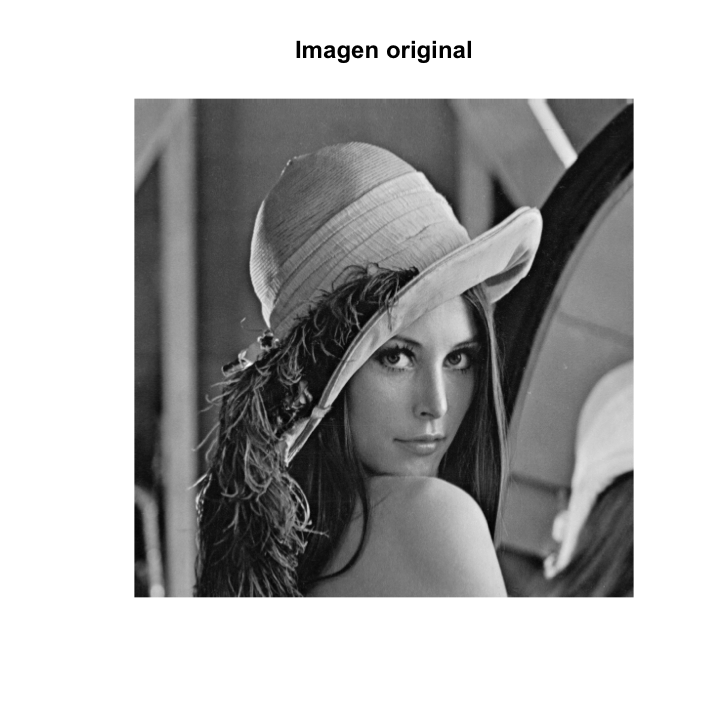

In [29]:
url <- "https://upload.wikimedia.org/wikipedia/en/7/7d/Lenna_%28test_image%29.png"
img <- grayscale(load.image(url))

options(repr.plot.width = 6, repr.plot.height = 6)
plot(img, main = "Imagen original", axes = FALSE)
dim(img)

`dim(img)` devuelve ancho, alto, profundidad (1 para imágenes planas) y canales de color (1 para escala de grises). Para operar con nuestras funciones convertimos la imagen a una matriz de $512\times512$ (la convolución *valid* devuelve $510\times510$).

Escribimos una función auxiliar que aplica un filtro y muestra el antes y el después.

In [30]:
mostrar_filtro <- function(img, filtro, titulo) {
  # as.matrix(img) queda como [x, y]: t() la pasa a [fila, columna] para aplicar el filtro
  # tal como se ve la imagen, y el segundo t() la devuelve al orden que espera as.cimg
  resultado <- t(convolve_image(t(as.matrix(img)), filtro))
  options(repr.plot.width = 12, repr.plot.height = 6)
  par(mfrow = c(1, 2), mar = c(2, 2, 2, 2))
  plot(img, main = "Original", axes = FALSE)
  plot(as.cimg(resultado), main = titulo, axes = FALSE)
  invisible(resultado)
}

### Suavizar (*blur*)

Un promedio simple de cada píxel con sus 8 vecinos:

$$ \frac{1}{9}\begin{bmatrix} 1 & 1 & 1 \\ 1 & 1 & 1 \\ 1 & 1 & 1 \end{bmatrix} $$

Con $3\times3$ el efecto es sutil; con un filtro más grande se nota más.

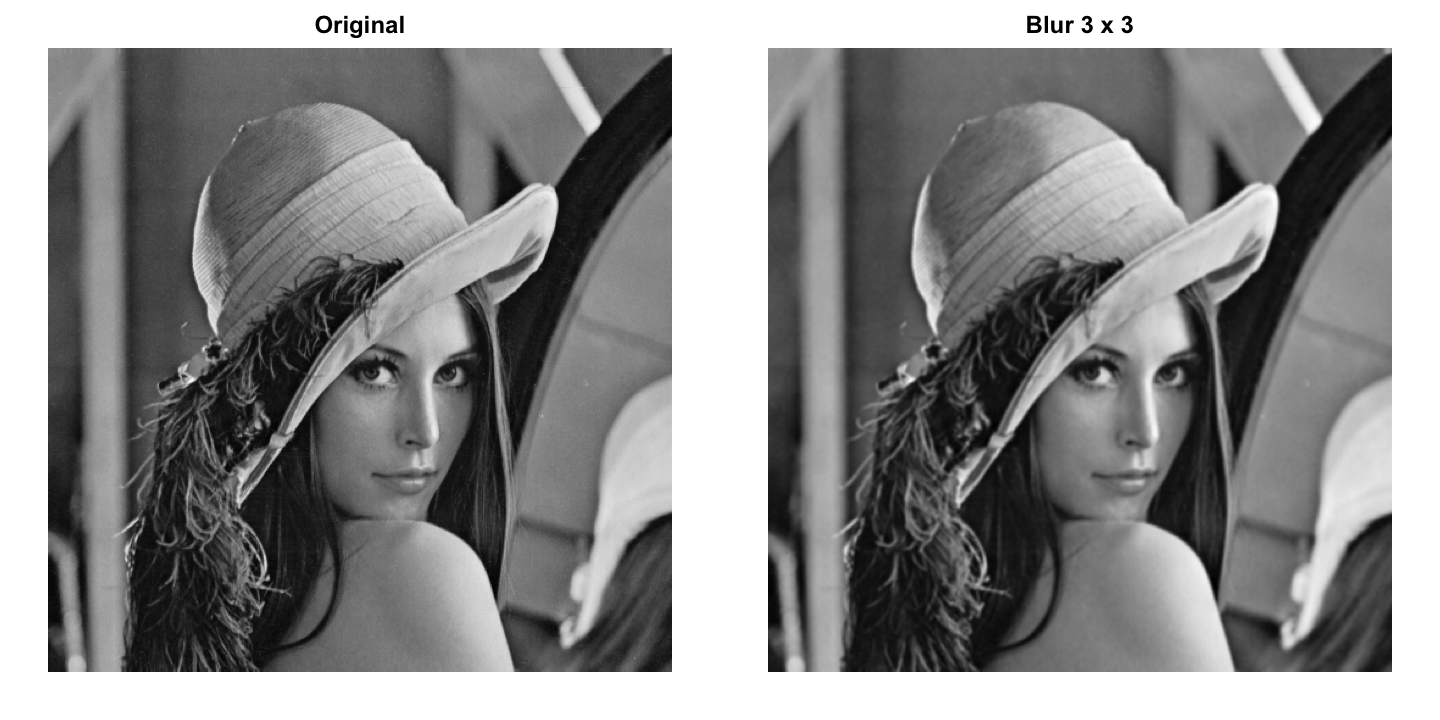

In [31]:
blur_3 <- matrix(1 / 9, nrow = 3, ncol = 3)
img_blur <- mostrar_filtro(img, blur_3, "Blur 3 x 3")

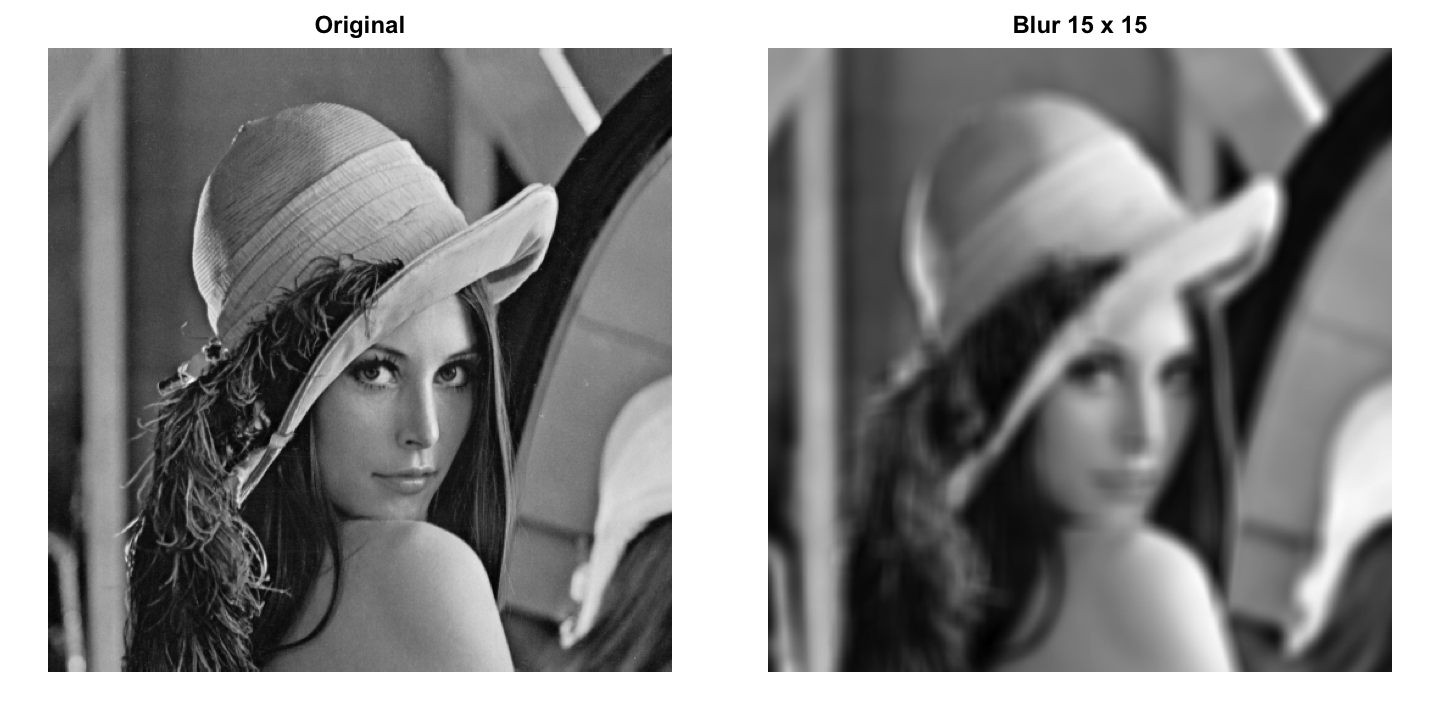

In [32]:
blur_15 <- matrix(1 / 225, nrow = 15, ncol = 15)
img_blur_15 <- mostrar_filtro(img, blur_15, "Blur 15 x 15")

### Bordes verticales

Una diferencia: resta la columna izquierda de la derecha. Vale cero en zonas uniformes y es grande (positivo o negativo) donde la intensidad cambia de izquierda a derecha.

$$ \begin{bmatrix} -1 & 0 & 1 \\ -1 & 0 & 1 \\ -1 & 0 & 1 \end{bmatrix} $$

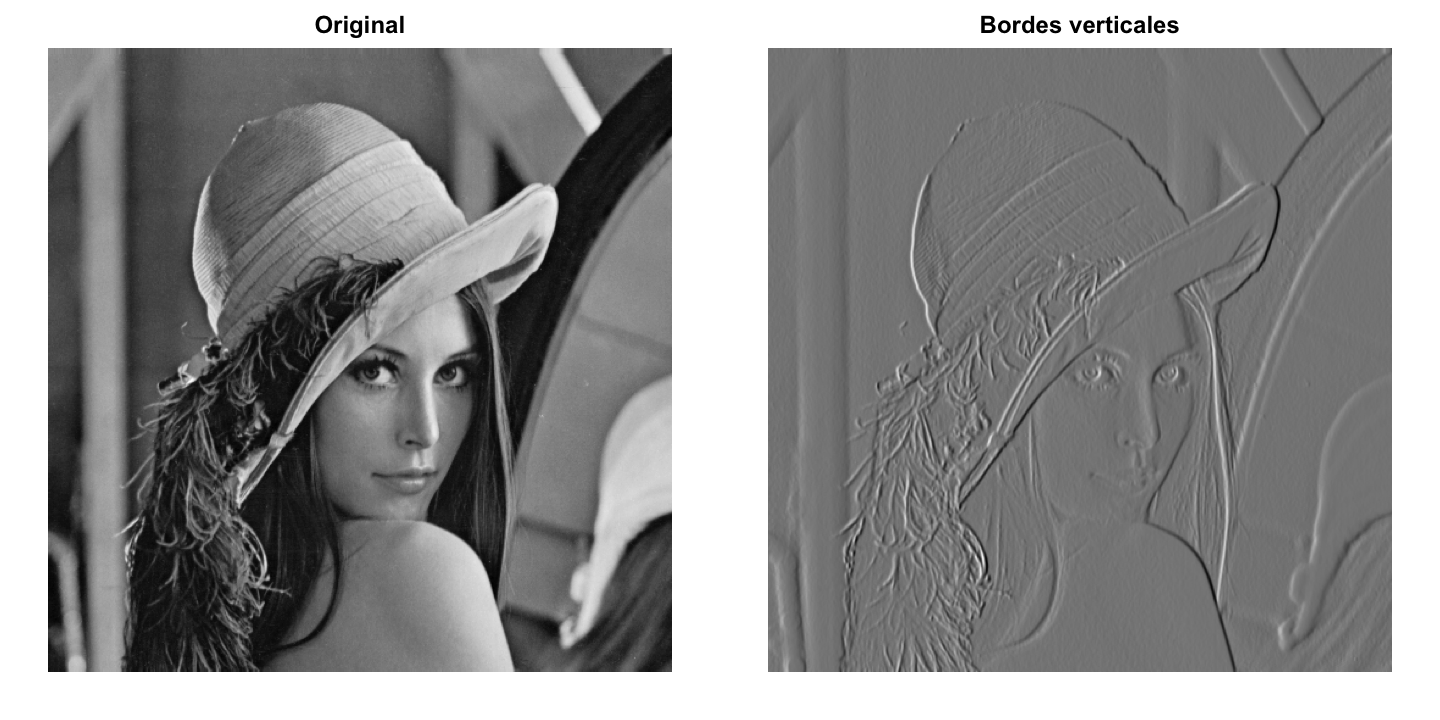

In [33]:
bordes_v <- matrix(c(-1, 0, 1,
                     -1, 0, 1,
                     -1, 0, 1), nrow = 3, byrow = TRUE)
img_bordes <- mostrar_filtro(img, bordes_v, "Bordes verticales")

### Líneas verticales y horizontales

Con un filtro grande (aquí $25\times25$) que tiene unos en la columna central, se resaltan las líneas verticales largas; con unos en la fila central, las horizontales.

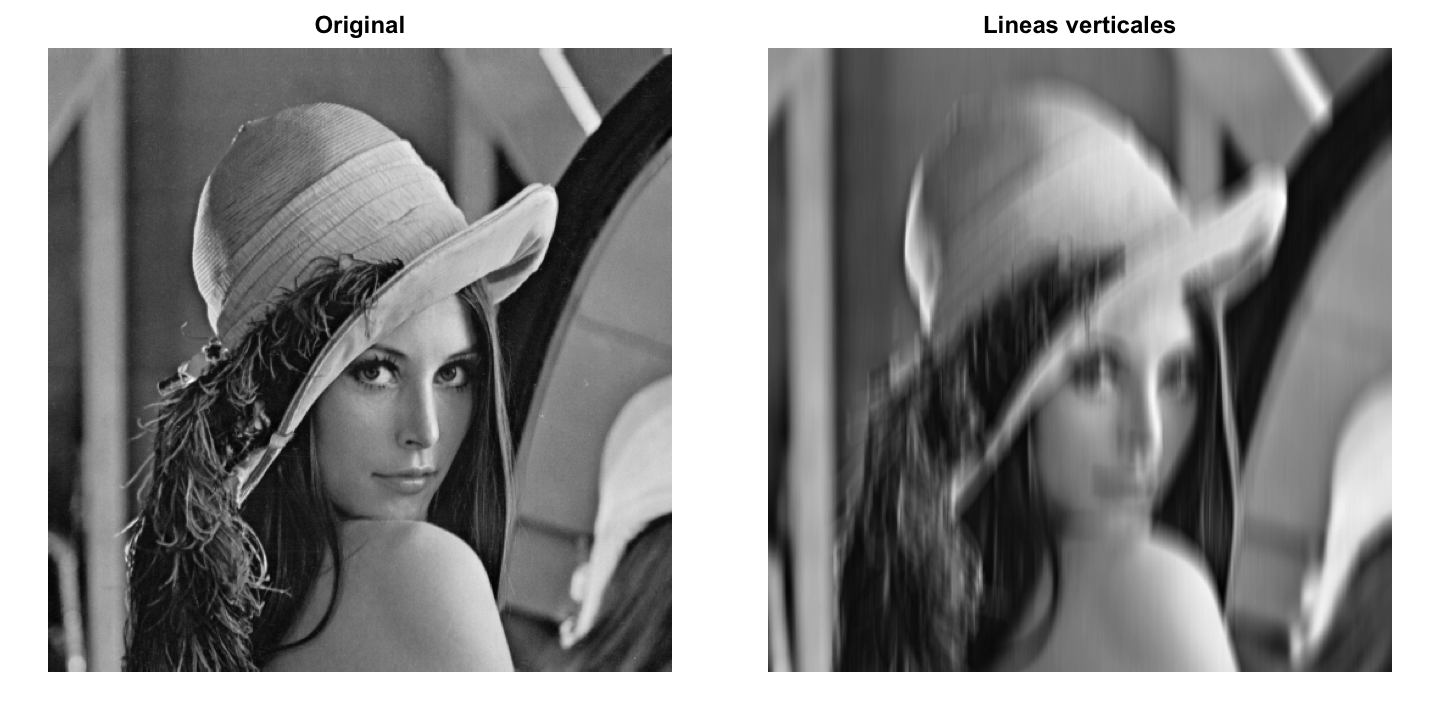

In [34]:
k <- 25
lineas_v <- matrix(0, nrow = k, ncol = k)
lineas_v[, ceiling(k / 2)] <- 1
img_lineas_v <- mostrar_filtro(img, lineas_v, "Lineas verticales")

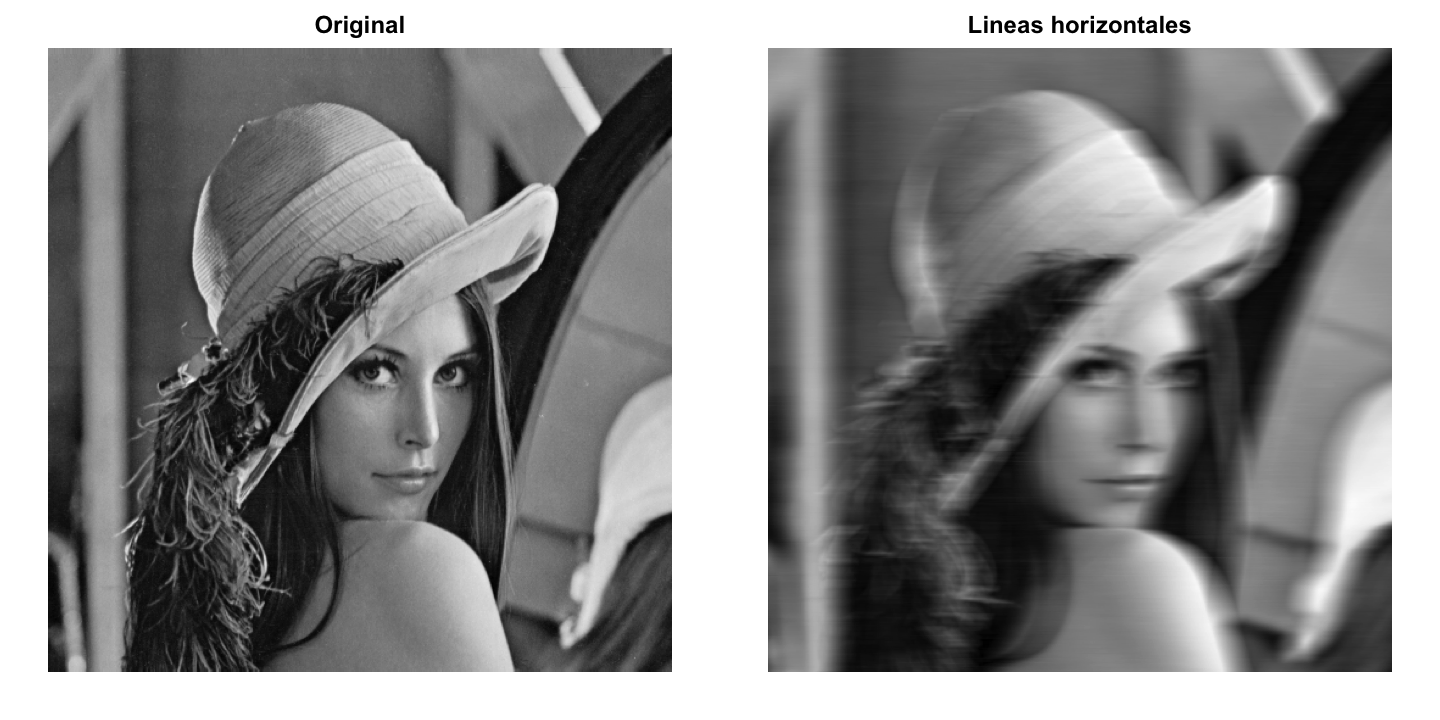

In [35]:
lineas_h <- matrix(0, nrow = k, ncol = k)
lineas_h[ceiling(k / 2), ] <- 1
img_lineas_h <- mostrar_filtro(img, lineas_h, "Lineas horizontales")

### Diagonales

Unos en la diagonal principal, o en la antidiagonal.

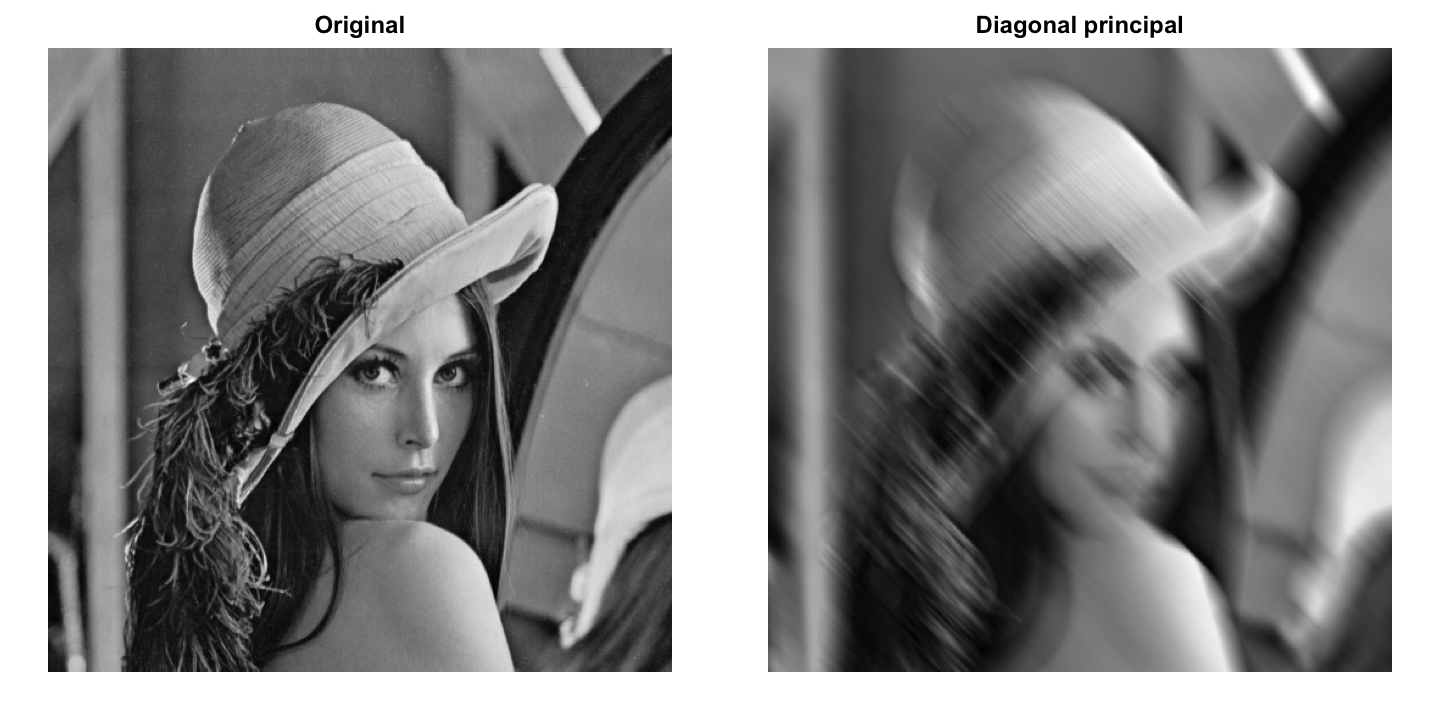

In [36]:
diagonal <- matrix(0, nrow = k, ncol = k)
diag(diagonal) <- 1
img_diag <- mostrar_filtro(img, diagonal, "Diagonal principal")

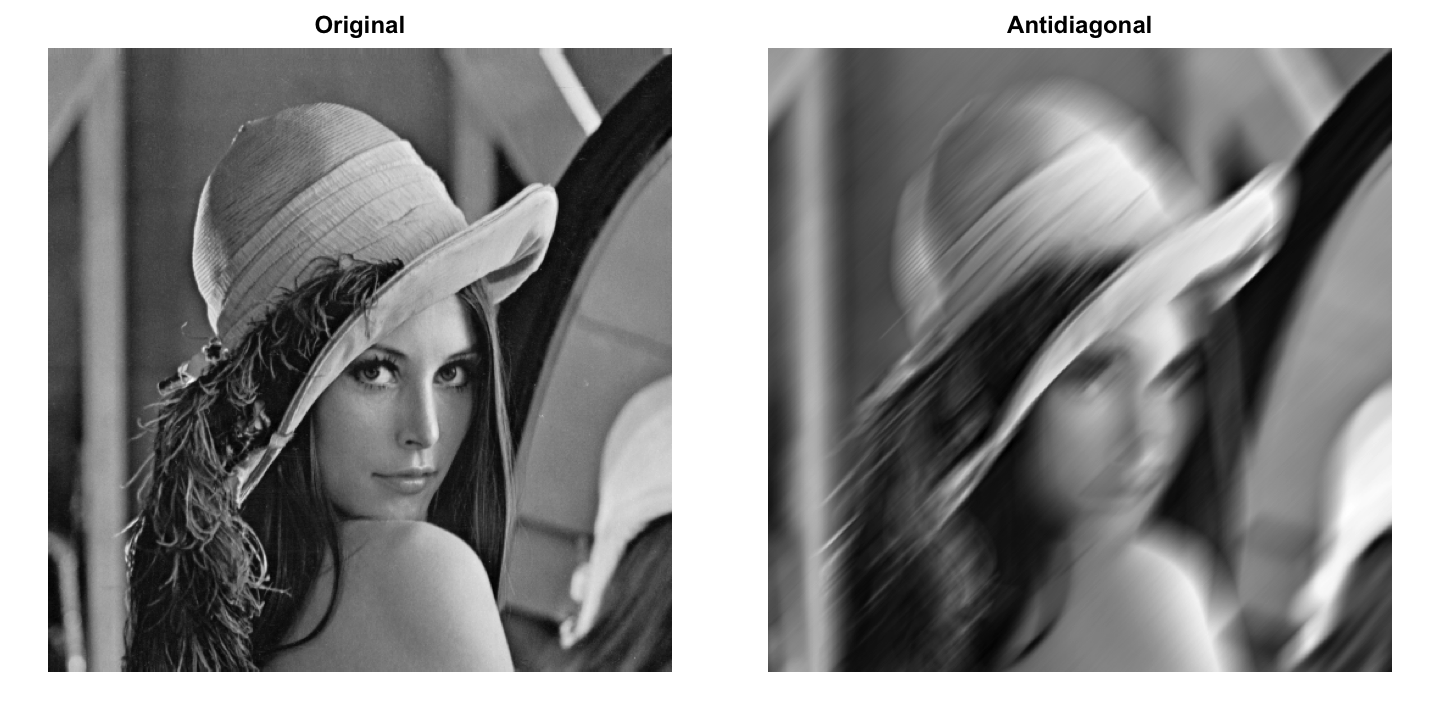

In [37]:
antidiagonal <- diagonal[, k:1]
img_antidiag <- mostrar_filtro(img, antidiagonal, "Antidiagonal")

### Contorno

Unos en el borde del filtro y ceros en el centro: resalta los contornos de los objetos.

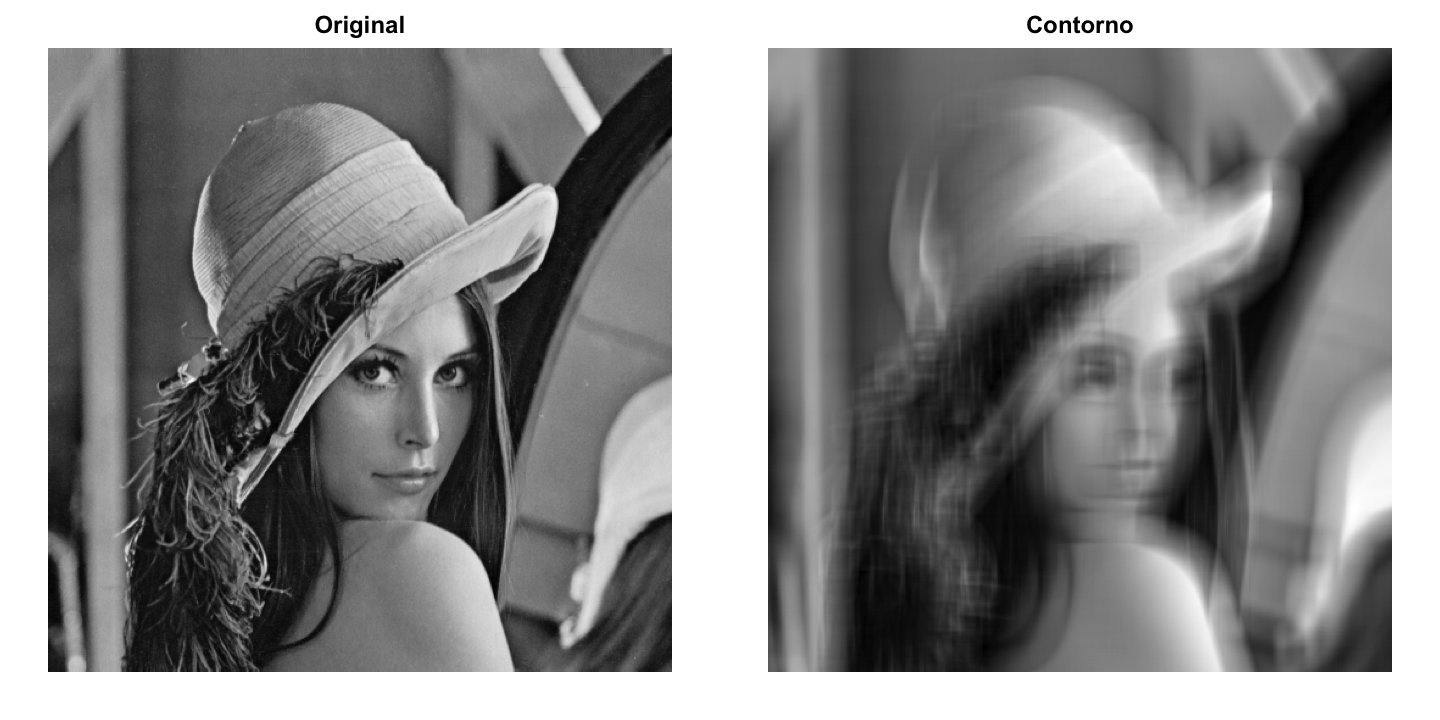

In [38]:
contorno <- matrix(1, nrow = k, ncol = k)
contorno[2:(k - 1), 2:(k - 1)] <- 0
img_contorno <- mostrar_filtro(img, contorno, "Contorno")

Cada filtro extrae un rasgo distinto de la misma imagen. Una CNN tiene decenas de filtros por capa, y en lugar de elegirlos a mano los **aprende** para la tarea.

## 3. Pooling

El *max pooling* resume cada bloque de $k\times k$ con su máximo. Los bloques **no se solapan**: el bloque avanza de a `stride` posiciones, y con `stride = k` cada píxel entra en un solo bloque.

$$ y_{ij} = \max_{(m,n)\,\in\,\text{bloque}(i,j)} x_{mn} $$

In [39]:
max_pooling_image <- function(img, k, stride = k) {
  if (inherits(img, "cimg")) img <- as.matrix(img)
  height <- nrow(img)
  width  <- ncol(img)
  pooled_height <- floor((height - k) / stride) + 1
  pooled_width  <- floor((width - k) / stride) + 1
  pooled <- matrix(0, nrow = pooled_height, ncol = pooled_width)
  for (i in seq_len(pooled_height)) {
    for (j in seq_len(pooled_width)) {
      filas    <- ((i - 1) * stride + 1):((i - 1) * stride + k)
      columnas <- ((j - 1) * stride + 1):((j - 1) * stride + k)
      pooled[i, j] <- max(img[filas, columnas])
    }
  }
  return(pooled)
}

### El ejemplo de las slides

Una matriz de $4\times4$ con bloques de $2\times2$: quedan cuatro valores, el máximo de cada bloque.

In [40]:
m <- matrix(c(1, 3, 2, 0,
              5, 6, 1, 4,
              7, 2, 9, 8,
              0, 1, 3, 2), nrow = 4, byrow = TRUE)

max_pooling_image(m, k = 2, stride = 2)

6,4
7,9


Y sobre el *feature map* de la O después de ReLU: de $4\times4$ a $2\times2$, los dos unos sobreviven.

In [41]:
max_pooling_image(feature_map_relu, k = 2, stride = 2)

1,0
0,1


### Sobre la imagen

Aplicamos pooling con bloques de $10\times10$ a la imagen de bordes verticales. La dimensión baja de $510\times510$ a $51\times51$, y la imagen sigue reconocible: el pooling descarta detalle y conserva dónde están las activaciones fuertes.

Antes del pooling: 510 510 
Despues del pooling: 51 51 


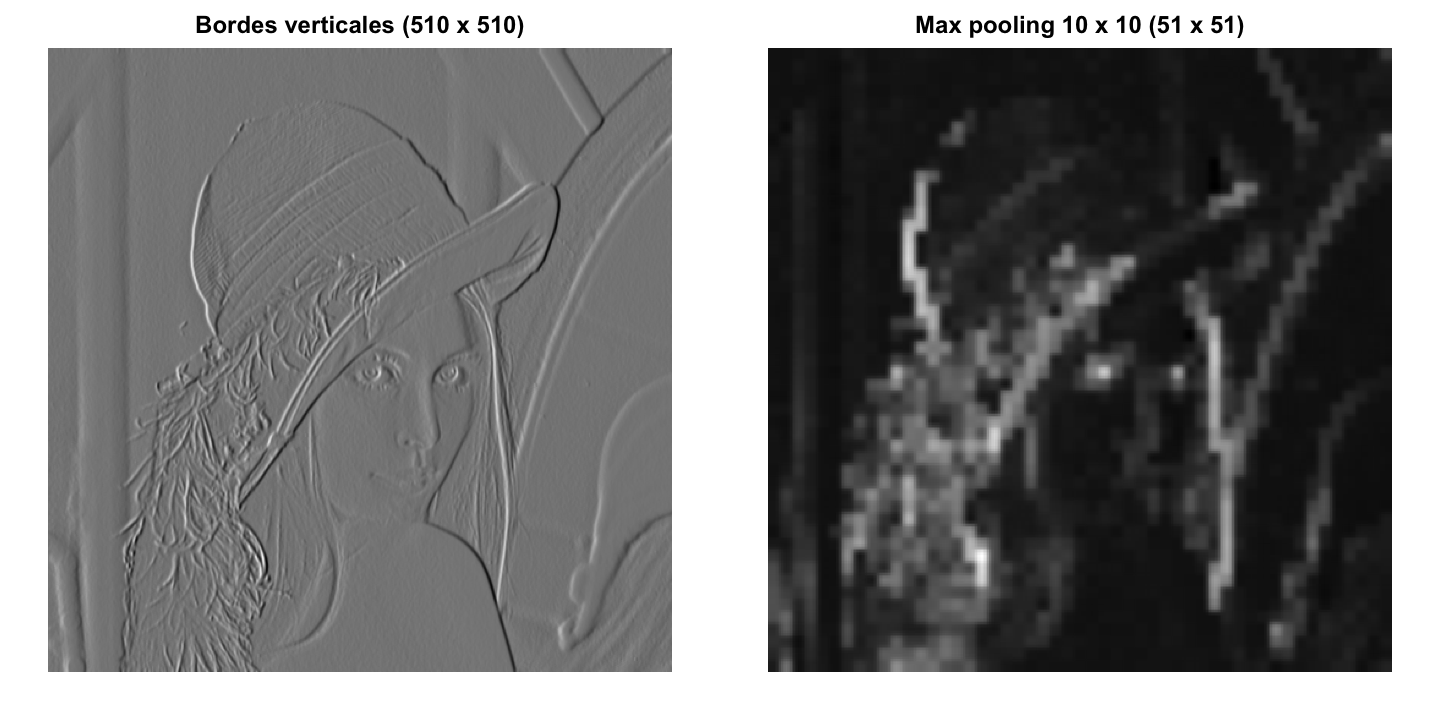

In [42]:
pooled <- max_pooling_image(img_bordes, k = 10, stride = 10)

cat("Antes del pooling:", dim(img_bordes), "\n")
cat("Despues del pooling:", dim(pooled), "\n")

options(repr.plot.width = 12, repr.plot.height = 6)
par(mfrow = c(1, 2), mar = c(2, 2, 2, 2))
plot(as.cimg(img_bordes), main = "Bordes verticales (510 x 510)", axes = FALSE)
plot(as.cimg(pooled), main = "Max pooling 10 x 10 (51 x 51)", axes = FALSE)

### Qué pasa si los bloques se solapan

Con `stride = 1` el bloque avanza de a un píxel y los bloques se superponen: la salida casi no se achica. En las CNN el pooling se usa con `stride = k` precisamente para reducir la dimensión.

In [43]:
dim(max_pooling_image(m, k = 2, stride = 1))
dim(max_pooling_image(m, k = 2, stride = 2))

[1] 3 3

[1] 2 2